<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Spirulina-based-Microcapsules-Control-Release/blob/main/Note_5_Feed_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cross_decomposition import PLSRegression

In [ ]:
final_plsr = joblib.load(
    "Release_Final_PLSR.pkl"
)

best_components = joblib.load(
    "Release_Best_PLS_Components.pkl"
)

print(best_components)

21


In [ ]:
X_train = joblib.load(
    "X_train_release.pkl"
)

X_test = joblib.load(
    "X_test_release.pkl"
)

y_train = joblib.load(
    "y_train_release.pkl"
)

y_test = joblib.load(
    "y_test_release.pkl"
)

In [ ]:
df = pd.read_excel(
    "Datasets Final.xlsx"
)

In [ ]:
wavelength_columns = []

# Use X_train columns to identify and extract wavelength values
for col in X_train.columns:
    if col.startswith('A_'):
        try:
            # Extract the numeric part after 'A_' and convert to float
            numeric_wavelength = float(col[2:])
            # Reconstruct the column name with 'A_' prefix, ensuring integer format for wavelength
            wavelength_columns.append(f'A_{int(numeric_wavelength)}')
        except ValueError:
            pass

print(
    len(wavelength_columns)
)

601


In [ ]:
# Re-execute this cell to re-train the PLSR model with corrected wavelength_columns
X_train_wavelength_data = X_train[wavelength_columns].astype(float)
final_plsr = PLSRegression(n_components=best_components)
final_plsr.fit(X_train_wavelength_data, y_train)
print("PLSR model re-trained successfully.")

PLSR model re-trained successfully.


In [ ]:
def calculate_vip(model):

    t = model.x_scores_

    w = model.x_weights_

    q = model.y_loadings_

    p, h = w.shape

    s = np.diag(
        t.T @ t @ q.T @ q
    )

    total_s = np.sum(s)

    vip = np.zeros(p)

    for i in range(p):

        weight = np.array([

            (w[i,j]**2)

            *

            s[j]

            for j in range(h)

        ])

        vip[i] = np.sqrt(

            p *

            np.sum(weight)

            /

            total_s

        )

    return vip

In [ ]:
vip_scores = calculate_vip(
    final_plsr
)

vip_df = pd.DataFrame({

    "Wavelength":
        wavelength_columns,

    "VIP":
        vip_scores

})

vip_df = vip_df.sort_values(

    "VIP",

    ascending=False

)

display(
    vip_df.head(20)
)

,Wavelength,VIP
454,A_654,2.684710
453,A_653,2.684132
455,A_655,2.680703
452,A_652,2.678973
456,A_656,2.673148
451,A_651,2.668672
457,A_657,2.660087
450,A_650,2.654814
458,A_658,2.643122
449,A_649,2.635188


In [ ]:
vip_df.to_excel(
    "VIP_Score.xlsx",
    index=False
)

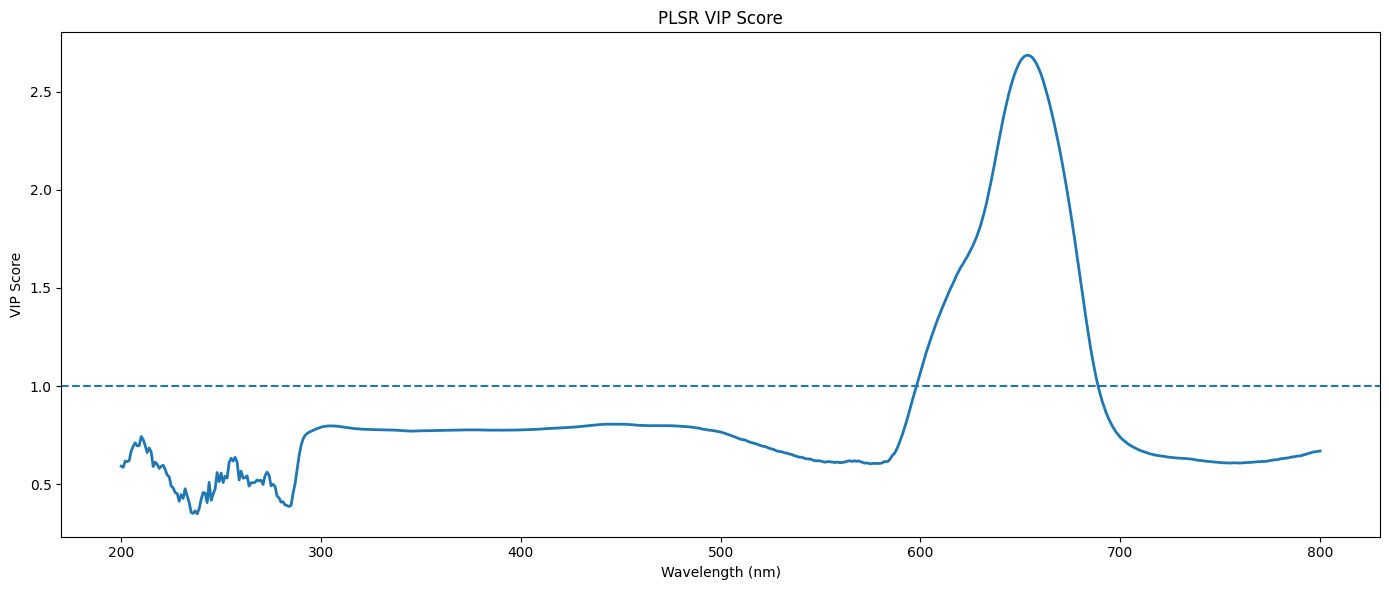

In [ ]:
plt.figure(
    figsize=(14,6)
)

plt.plot(

    [float(x[2:]) for x in wavelength_columns],

    vip_scores,

    linewidth=2

)

plt.axhline(

    1,

    linestyle="--"

)

plt.xlabel(
    "Wavelength (nm)"
)

plt.ylabel(
    "VIP Score"
)

plt.title(
    "PLSR VIP Score"
)

plt.tight_layout()

plt.show()

In [ ]:
important_vip = vip_df[
    vip_df["VIP"] > 1
]

display(
    important_vip
)

,Wavelength,VIP
454,A_654,2.684710
453,A_653,2.684132
455,A_655,2.680703
452,A_652,2.678973
456,A_656,2.673148
...,...,...
401,A_601,1.106664
487,A_687,1.091087
400,A_600,1.070074
488,A_688,1.041163


In [ ]:
top20 = vip_df.head(20)

display(top20)

top20.to_excel(
    "Top20_Wavelength.xlsx",
    index=False
)

,Wavelength,VIP
454,A_654,2.684710
453,A_653,2.684132
455,A_655,2.680703
452,A_652,2.678973
456,A_656,2.673148
451,A_651,2.668672
457,A_657,2.660087
450,A_650,2.654814
458,A_658,2.643122
449,A_649,2.635188


In [ ]:
coef = final_plsr.coef_.flatten()

In [ ]:
coef_df = pd.DataFrame({

    "Wavelength":
        wavelength_columns,

    "Coefficient":
        coef

})

coef_df.to_excel(
    "PLSR_Coefficient.xlsx",
    index=False
)

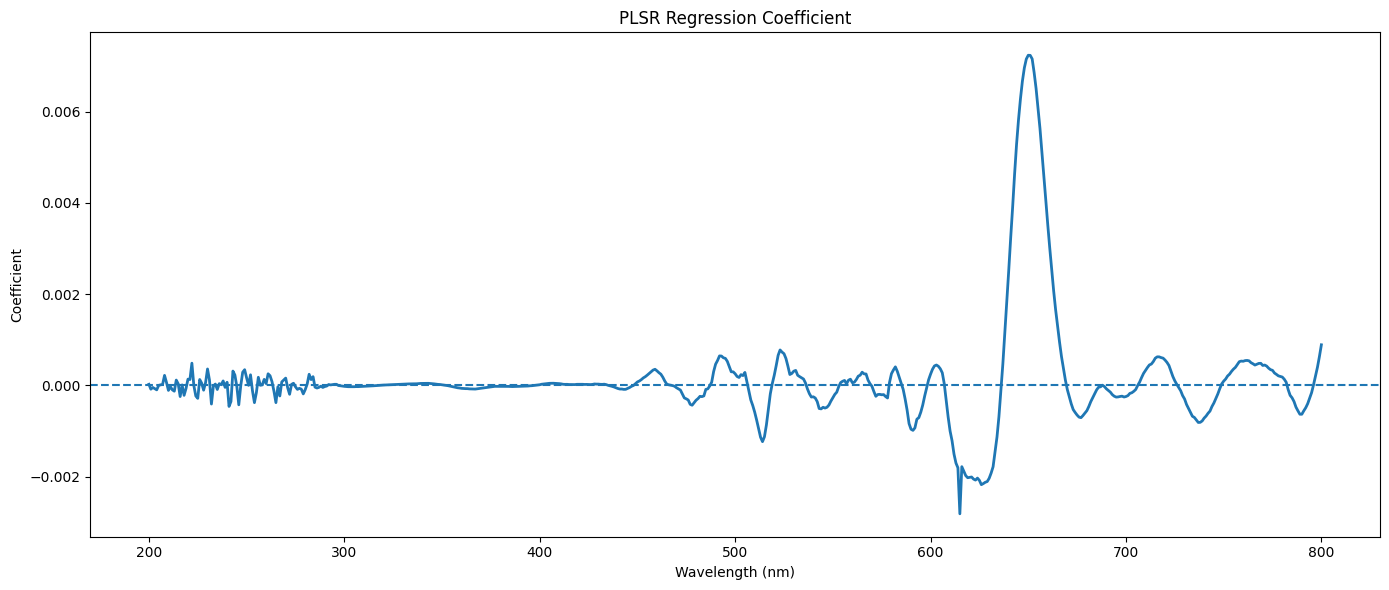

In [ ]:
plt.figure(
    figsize=(14,6)
)

plt.plot(

    [float(x[2:]) for x in wavelength_columns],

    coef,

    linewidth=2

)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Wavelength (nm)"
)

plt.ylabel(
    "Coefficient"
)

plt.title(
    "PLSR Regression Coefficient"
)

plt.tight_layout()

plt.show()

In [ ]:
vip_region = vip_df.copy()

vip_region["Wavelength"] = (
    vip_region["Wavelength"]
    .apply(lambda x: float(x[2:]))
)

In [ ]:
conditions = [

    (vip_region["Wavelength"] >= 200)
    &
    (vip_region["Wavelength"] < 300),

    (vip_region["Wavelength"] >= 300)
    &
    (vip_region["Wavelength"] < 500),

    (vip_region["Wavelength"] >= 500)
    &
    (vip_region["Wavelength"] < 700),

    (vip_region["Wavelength"] >= 700)
    &
    (vip_region["Wavelength"] <= 800)

]

In [ ]:
labels = [

    "Protein Region",

    "Pigment Region",

    "Phycobiliprotein Region",

    "Scattering Region"

]

In [ ]:
vip_region["Region"] = np.select(

    conditions,

    labels,

    default="Other"

)

In [ ]:
region_importance = (

    vip_region

    .groupby("Region")["VIP"]

    .mean()

    .reset_index()

    .sort_values(

        "VIP",

        ascending=False

    )

)

display(
    region_importance
)

,Region,VIP
0,Phycobiliprotein Region,1.237992
1,Pigment Region,0.785278
3,Scattering Region,0.637920
2,Protein Region,0.550244


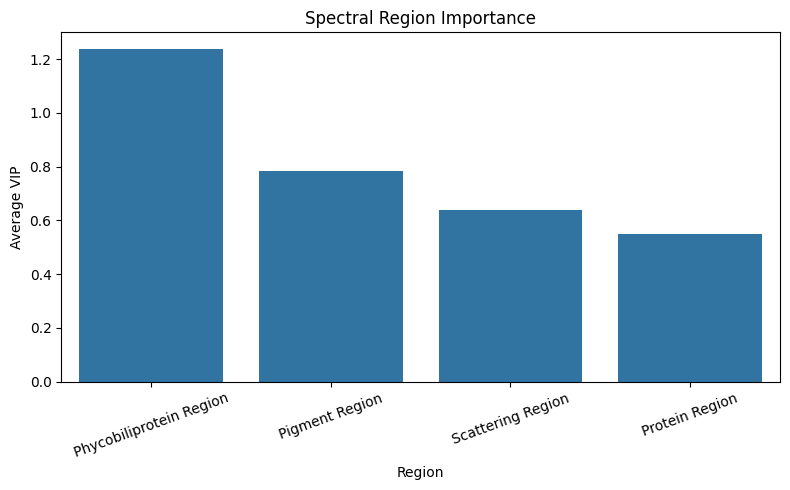

In [ ]:
plt.figure(
    figsize=(8,5)
)

sns.barplot(

    data=region_importance,

    x="Region",

    y="VIP"

)

plt.ylabel(
    "Average VIP"
)

plt.title(
    "Spectral Region Importance"
)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [ ]:
region_importance.to_excel(

    "Region_Importance.xlsx",

    index=False

)

In [ ]:
selected_wave = list(
    top20["Wavelength"]
)

In [ ]:
X_df = pd.DataFrame(

    X_train,

    columns=wavelength_columns

)

In [ ]:
corr_df = X_df[
    selected_wave
].corr()

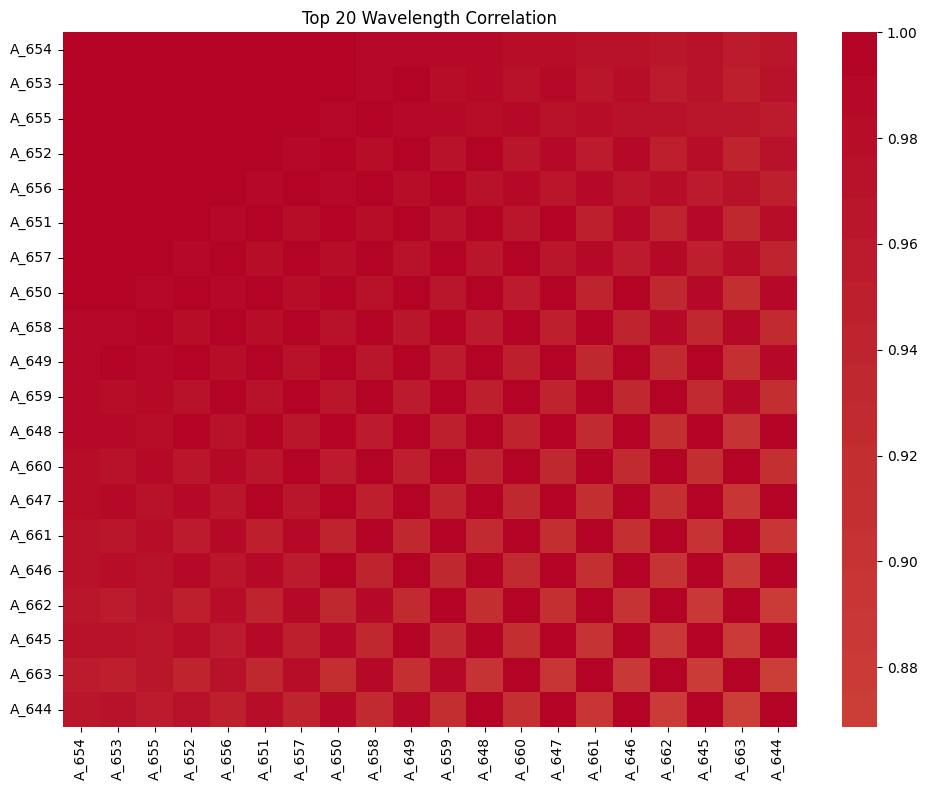

In [ ]:
plt.figure(
    figsize=(10,8)
)

sns.heatmap(

    corr_df,

    cmap="coolwarm",

    center=0

)

plt.title(
    "Top 20 Wavelength Correlation"
)

plt.tight_layout()

plt.show()